**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Tutorial 0, notebook 3 of 3

| | |
|---|---|
| **Goal** | Describe your sector: volume and growth, technology mix and geography, at family and application level. |
| **Before this** | 01 · PATSTAT basics, and the CPC codes and keywords of your sector from Step 0 |
| **Time** | 30 min |
| **PATSTAT environment** | TEST (switch to PROD for final numbers) |

← [01 · PATSTAT on TIP](01_patstat_basics.ipynb) &nbsp;|&nbsp; — →

# Step 1 of the PW: General description of the sector

| Question to answer (Presentation deck, Step 1) | How we measure it in this notebook |
|---|---|
| How big is the field, and is it growing, flat or declining? | Families/patent applications per earliest priority year/appliation year and applications per filing year; growth (%) of the sector compared with the growth (%) of all patents |
| Which technologies make up the field? Which classes dominate, and how is the mix shifting? | Fractional counts by CPC subclass, and by WIPO technology field, over time |
| Where is it happening? | Filing offices (IP5); applicant and inventor countries (fractional counts) |
| Is the field patent-heavy, or does it rely on secrecy? | Compare, for instance, with a similar field |

## 1. Setup and configuration

In [1]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, literal, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # import the needed tables for the extractions
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
)

## 1.1 Sector Definition

A patent family belongs to the sector if it matches CPC codes OR keywords in the title/abstract:

$$\text{Precision Agriculture} = \text{Keywords} \cup \text{IPC} \cup \text{CPC}$$

In [2]:
# ---------------------------------------------------------------- environment
ENV = "PROD"                 # develop on TEST, switch to "PROD" for the final numbers
OUTPUT_DIR = Path("outputs/step1") # name this how you wish

# ---------------------------------------------------------------- sector definition
SECTOR_NAME = "Precision Agriculture"
SECTOR_CPC_PREFIXES = (      
"A01B79/005",
"A01B69",
"A01D41/127",
"A01C7/102"
    
)
SECTOR_KEYWORDS = (     
     "precision agriculture", "precision farming", "precision agricultural",
    "smart farming", "digital agriculture",
    "variable rate application", "variable-rate application", "variable rate seeding",
    "variable rate fertili", "site-specific", "site specific farming",
    "prescription map", "yield map", "yield monitor", "yield sensor",
    "weed detection", "weed map", "crop row", "row guidance", "crop sensing",
    "agricultural machine guidance", "automatic steering of agricultural",

)

# ---------------------------------------------------------------- time window, you can choose and change!!
YEAR_MIN, YEAR_MAX = 2000, 2025

# Which year to use (see Section 3). Three columns of tls201_appln can date a patent:
#   "appln_filing_year"    year this application was filed
#   "earliest_publn_year"  year of the first publication
#   "earliest_filing_year" earliest priority year (first filing of the invention, anywhere)
FAMILY_TIME_COLUMN = "earliest_filing_year"   # family level: the earliest one in the family (PW rule)
APPLN_TIME_COLUMN = "appln_filing_year"       # application level: the application's own filing year

# Last years that are still incomplete in PATSTAT, for each choice of year
TRUNCATED_YEARS = {"appln_filing_year": 3, "earliest_filing_year": 3, "earliest_publn_year": 1}

# ---------------------------------------------------------------- counting rules
IPR_TYPE = "PI"                                  # patents of invention only (excludes utility models "UM")
IP5_OFFICES = ("EP", "US", "CN", "JP", "KR")     # the five largest patent offices (Section 9)
TOP_N = 8                                        # categories shown in tables and figures; the rest is "Other"

# ---------------------------------------------------------------- derived
LAST_COMPLETE_YEAR = YEAR_MAX - max(TRUNCATED_YEARS[FAMILY_TIME_COLUMN], TRUNCATED_YEARS[APPLN_TIME_COLUMN])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

patstat = PatstatClient(env=ENV)
db = patstat.orm()
print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} "
      f"| family year: {FAMILY_TIME_COLUMN} | application year: {APPLN_TIME_COLUMN} "
      f"| complete years up to {LAST_COMPLETE_YEAR}")

Sector: Precision Agriculture | env: PROD | years 2000-2025 | family year: earliest_filing_year | application year: appln_filing_year | complete years up to 2022


## 2. Two levels of analysis: applications and families

Before counting anything, we must decide **what we count**. PATSTAT offers two natural units.

**An application (`appln_id`)** is one request for protection filed at one patent office. Each row of `tls201_appln` is an application, identified by `appln_id`. The office is in `appln_auth` (e.g. `EP` = European Patent Office, `US`, `CN`, `IT`, and `WO` for an international application filed through the PCT, see Section 4).

**A family (`docdb_family_id`)** groups all the applications that protect the **same invention** in different offices. A patent is valid only in the country that grants it: to be protected in several countries, an applicant files the same invention in several offices, and each filing becomes a separate application. PATSTAT links them with the same `docdb_family_id`.

**A toy example.** An Italian company invents a new wave energy converter:

| Step | Office (`appln_auth`) | Filing year | `appln_id` | `docdb_family_id` |
|---|---|---|---|---|
| first filing (the **priority**) | IT | 2019 | 101 | 9001 |
| international application through the PCT, within 12 months | WO | 2020 | 102 | 9001 |
| European application | EP | 2021 | 103 | 9001 |
| national applications | US, CN | 2021 | 104, 105 | 9001 |

5 applications, **1 invention**. Counting applications gives 5, counting families gives 1.

| | Application level (`appln_id`) | Family level (`docdb_family_id`) |
|---|---|---|
| What one unit is | a filing at one office | an invention |
| Answers questions like | How much protection is sought, and where? | How many inventions are produced, by whom, in which technologies? |
| Watch out | an invention filed in many offices counts many times | each invention counts once |
| Year used here | the application's filing year | the earliest priority year of the family |

Either the  **family or application id could be the reference units for the PW** (one invention = one count). In this notebook every plot is shown at **both levels**, side by side, so you can see how much the picture changes.

The sector is always selected at family level: a family belongs to the sector if any of its applications has one of the sector CPC codes. At application level we then count all the applications of those families. So the two levels look at the same patents and differ only in *how we count*.

### 2.1 Selecting the sector



In [3]:
# These are just examples you can write your own functions with your own rules

def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


def keyword_condition(terms):
    """OR-condition: any term appears in the title or abstract (case-insensitive)."""
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*(col.like(f"%{t.lower()}%") for t in terms for col in (title, abstract)))


def sector_family_ids(cpc_prefixes=SECTOR_CPC_PREFIXES, keywords=SECTOR_KEYWORDS):
    """Query of the docdb_family_ids that belong to the sector (CPC codes OR keywords)."""
    family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
    by_cpc = (
        db.query(family_id)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, cpc_prefixes))
    )
    if not keywords:
        return by_cpc.distinct()
    by_keywords = (
        db.query(family_id)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(keywords))
    )
    return by_cpc.union(by_keywords)   # UNION removes duplicates


sector_ids = sector_family_ids()

### 2.2 Example: one real family, application by application

Let us look at the sector family with the most applications. Each row is one `appln_id`; they all share the same `docdb_family_id`.

In [4]:
n_applications = func.count(TLS201_APPLN.appln_id)
largest_family = (
    db.query(TLS201_APPLN.docdb_family_id, n_applications.label("n_applications"))
    .filter(TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .order_by(n_applications.desc())
    .limit(1)
)
example_family_id = int(patstat.df(largest_family).loc[0, "docdb_family_id"])

example_family = patstat.df(
    db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_kind,
        TLS201_APPLN.appln_filing_date,
        TLS201_APPLN.appln_filing_year,
        TLS201_APPLN.earliest_publn_year,
        TLS201_APPLN.earliest_filing_year,
        TLS201_APPLN.granted,
        TLS201_APPLN.docdb_family_size,
    )
    .filter(TLS201_APPLN.docdb_family_id == example_family_id)
    .order_by(TLS201_APPLN.appln_filing_date)
)
example_family

,docdb_family_id,appln_id,appln_auth,appln_kind,appln_filing_date,appln_filing_year,earliest_publn_year,earliest_filing_year,granted,docdb_family_size
0,49624232,521363476,MX,A,2013-03-15,2013,2019,2012,Y,225
1,49624232,506353317,SG,A,2013-03-15,2013,2018,2012,N,225
2,49624232,481505178,DK,T,2013-03-15,2013,2017,2012,Y,225
3,49624232,446689323,MX,A,2013-03-15,2013,2015,2012,Y,225
4,49624232,503796114,HU,A,2013-03-15,2013,2018,2012,N,225
...,...,...,...,...,...,...,...,...,...,...
220,49624232,601498565,AU,A,2023-10-11,2023,2023,2012,N,225
221,49624232,622998599,US,A,2024-06-24,2024,2024,2012,N,225
222,49624232,629458397,US,A,2024-10-25,2024,2025,2012,N,225
223,49624232,630574722,US,A,2025-01-03,2025,2025,2012,N,225


How to read it:

- `appln_auth` tells you in which offices the invention was filed: this is **where protection is sought**.
- `appln_kind` is the type of application: `A` for a patent application, `W` for an international application filed through the PCT (codes are 2 characters long, e.g. `'A '`).
- `granted` = `Y` if that application was granted. Each office decides on its own: the same invention can be granted in one office and refused in another.
- `docdb_family_size` is the number of applications in the family: it is the same on every row.

## 3. Which year? Three ways to date a patent

Each application in `tls201_appln` carries three years. The same invention can therefore be placed in different years depending on the column you choose.

| Column | What it is | Use it when… | Incomplete recent years |
|---|---|---|---|
| `appln_filing_year` | year **this application** was filed at its office | you count applications | ~3 years (applications become visible only after publication, ~18 months) |
| `earliest_publn_year` | year of the **first publication** of the application | you want the most up-to-date series (EPO statistics use it) | only the current year |
| `earliest_filing_year` | year of the **earliest priority**: the first filing of the invention anywhere in the world | you want the date closest to the invention | ~3 years |

At **family level** we need one year per family: we take the **smallest `earliest_filing_year`** among its applications, i.e. the first time the invention was filed anywhere (PW rule). At **application level** we use the application's own `appln_filing_year`. Both choices can be changed in the configuration (`FAMILY_TIME_COLUMN`, `APPLN_TIME_COLUMN`).


On our example family:

In [5]:
years = example_family[["appln_id", "appln_auth", "appln_filing_year", "earliest_publn_year", "earliest_filing_year"]]
family_year = example_family["earliest_filing_year"].min()
print(f"Family {example_family_id}: {len(example_family)} applications filed between "
      f"{example_family['appln_filing_year'].min()} and {example_family['appln_filing_year'].max()}; "
      f"family year (earliest priority) = {family_year}")
years

Family 49624232: 225 applications filed between 2013 and 2025; family year (earliest priority) = 2012


,appln_id,appln_auth,appln_filing_year,earliest_publn_year,earliest_filing_year
0,521363476,MX,2013,2019,2012
1,506353317,SG,2013,2018,2012
2,481505178,DK,2013,2017,2012
3,446689323,MX,2013,2015,2012
4,503796114,HU,2013,2018,2012
...,...,...,...,...,...
220,601498565,AU,2023,2023,2012
221,622998599,US,2024,2024,2012
222,629458397,US,2024,2025,2012
223,630574722,US,2025,2025,2012


At application level this family adds one count to each of the filing years above; at family level it adds a single count, to its priority year. Section 7.1 shows the effect on the whole sector.

## 4. Other methodological choices

These choices are the same for every number in the notebook. State them in the technical appendix of your deck.

**Truncation.** Applications are published 18 months after the priority date and reach PATSTAT with a further delay, so the last ~3 filing or priority years are incomplete (`LAST_COMPLETE_YEAR` in the configuration). They are **shaded in grey in every figure and excluded from growth**: a drop in those years is not a decline of the sector.

**International applications through the PCT.** The Patent Cooperation Treaty (PCT) lets an applicant file **one international application**, handled by WIPO, that can later be extended to more than 150 countries. In PATSTAT it has `appln_auth = 'WO'` and `appln_kind` starting with `W`. Filing through the PCT costs money, so it signals an invention the applicant wants to protect abroad.

| | Family level | Application level |
|---|---|---|
| "via PCT" means… | the family has at least one PCT application | the application is itself a PCT application |

**Fractional counting.** In this code, when a family has applicants from different countries, each country receives a fraction of the family, proportional to its number of distinct applicants. For example, a family with 2 Italian applicants and 1 German applicant counts 2/3 for IT and 1/3 for DE. Each family then sums to exactly 1. The same rule applies to inventors and to technology classes: a family in 4 CPC subclasses gives 1/4 to each. At application level the same rule splits each application.



## 5. Tables and attributes used in Step 1

All tables join on `appln_id` (application level), except `tls206_person`, which joins `tls207_pers_appln` on `person_id`.

| Table | Grain (one row per…) | Attributes used | Used for |
|---|---|---|---|
| `tls201_appln` | application | `appln_id` (application key), `docdb_family_id` (family key), `appln_auth` (office), `appln_kind`, `ipr_type`, `appln_filing_year`, `earliest_publn_year`, `earliest_filing_year`, `granted`, `docdb_family_size` | the two levels, the three years, offices, PCT, grant rate, family size |
| `tls224_appln_cpc` | application × CPC symbol | `cpc_class_symbol` | sector definition; CPC subclass mix |
| `tls202_appln_title`, `tls203_appln_abstr` | application | `appln_title`, `appln_abstract` | optional keyword part of the sector definition |
| `tls207_pers_appln` | application × person × role | `person_id`, `applt_seq_nr` (> 0: applicant), `invt_seq_nr` (> 0: inventor) | who is an applicant, who is an inventor |
| `tls206_person` | person | `person_ctry_code`, `psn_name`, `psn_sector` | applicant and inventor countries; names for Step 2 |
| `tls230_appln_techn_field` | application × technology field | `techn_field_nr` (1–35), `weight` (sums to 1 per application) | WIPO technology fields |
| `tls901_techn_field_ipc` | IPC main group | `techn_field_nr`, `techn_field`, `techn_sector` | names of the 35 fields and of the 5 technology sectors |

Things to know about these attributes:

- `cpc_class_symbol` is padded with blanks (`F03B  13/14`): we strip blanks before matching, as in Tutorial 0. The **subclass** is the first 4 characters (`F03B`).
- `appln_kind` is a 2-character field (`'A '`), so `appln_kind == 'A'` fails: use `LIKE 'A%'`.
- `person_ctry_code` can be **empty (`''`) as well as `NULL`**: both are treated as unknown and excluded from country counts (their number is reported).
- The same real applicant can appear under several `person_id`s. Fractional counts are computed on distinct `person_id`s; name harmonisation (`psn_name`, `han_name`) is the topic of Step 2.

## 6. Some other examples to look at

You do not need to understand every line of this section to use the notebook: run it, then read Sections 7–9, where the results are.

### 6.1 Scopes

A **scope** is a query with one row per counting unit (`unit_id`) and its `year`:

- at **family level**, `unit_id` is the `docdb_family_id` and `year` is the family's earliest priority year;
- at **application level**, `unit_id` is the `appln_id` and `year` is its filing year.

We build four scopes, {family, application} × {all patents, sector}. "All patents" is the benchmark: the sector is compared with it. All calculations run inside the database, and only small result tables are downloaded.

In [6]:
IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%"))
LEVELS = ("family", "application")
UNIT_LABEL = {"family": "families", "application": "applications"}


def _restrict(q, family_ids):
    """Keep only the families in family_ids (None = all patents)."""
    if family_ids is None:
        return q
    return q.filter(TLS201_APPLN.docdb_family_id.in_(family_ids.subquery().select()))


def family_scope(family_ids=None):
    """Family level: one row per DOCDB family."""
    year = func.min(getattr(TLS201_APPLN, FAMILY_TIME_COLUMN))
    q = db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        year.label("year"),
        func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
        func.max(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("is_granted"),
        func.max(TLS201_APPLN.docdb_family_size).label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    return (
        _restrict(q, family_ids)
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(year.between(YEAR_MIN, YEAR_MAX))
        .subquery()
    )


def application_scope(family_ids=None, time_column=APPLN_TIME_COLUMN):
    """Application level: one row per appln_id, dated by its own time_column."""
    year = getattr(TLS201_APPLN, time_column)
    q = db.query(
        TLS201_APPLN.appln_id.label("unit_id"),
        year.label("year"),
        case((IS_PCT_APPLN, 1), else_=0).label("is_pct"),
        case((TLS201_APPLN.granted == "Y", 1), else_=0).label("is_granted"),
        TLS201_APPLN.docdb_family_size.label("family_size"),
    ).filter(TLS201_APPLN.ipr_type == IPR_TYPE, year.between(YEAR_MIN, YEAR_MAX))
    return _restrict(q, family_ids).subquery()


@dataclass(frozen=True)
class Scope:
    name: str     # "all patents" or the sector name
    level: str    # "family" or "application"
    sq: object    # SQLAlchemy subquery, one row per unit


SCOPES = [
    Scope("all patents", "family", family_scope()),
    Scope(SECTOR_NAME, "family", family_scope(sector_ids)),
    Scope("all patents", "application", application_scope()),
    Scope(SECTOR_NAME, "application", application_scope(sector_ids)),
]
SECTOR_SCOPES = [s for s in SCOPES if s.name == SECTOR_NAME]   # family first, then application

### 6.2 Counting functions

Each function takes a scope and returns a small `DataFrame` with the columns `scope` and `level`. Counts are in `n` (whole units) or `n_frac` (fractional units).

In [7]:
def _join_applications(q, scope):
    """Join the applications of each unit: all applications of a family, or the application itself."""
    key = TLS201_APPLN.docdb_family_id if scope.level == "family" else TLS201_APPLN.appln_id
    return q.join(TLS201_APPLN, key == scope.sq.c.unit_id).filter(TLS201_APPLN.ipr_type == IPR_TYPE)


def _tag(df, scope):
    return df.assign(scope=scope.name, level=scope.level)


def count_per_year(scope, only_pct=False):
    """Number of units (families or applications) per year; only_pct keeps those via PCT."""
    sq = scope.sq
    q = db.query(sq.c.year, func.count().label("n")).group_by(sq.c.year).order_by(sq.c.year)
    if only_pct:
        q = q.filter(sq.c.is_pct == 1)
    return _tag(patstat.df(q), scope)


def _split_equally(scope, unit_category, category):
    """Fractional counting: each unit is split equally across its distinct categories (sums to 1)."""
    pairs = unit_category.distinct().subquery()
    k = db.query(pairs.c.unit_id, func.count().label("k")).group_by(pairs.c.unit_id).subquery()
    q = (
        db.query(getattr(pairs.c, category), pairs.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == pairs.c.unit_id)
        .group_by(getattr(pairs.c, category), pairs.c.year)
    )
    return _tag(patstat.df(q), scope)


def fractional_by_country(scope, role="applicant"):
    """Fractional counts by person country and year (role: 'applicant' or 'inventor').

    Each unit is split among its distinct persons with a known country.
    """
    sq = scope.sq
    seq_nr = TLS207_PERS_APPLN.applt_seq_nr if role == "applicant" else TLS207_PERS_APPLN.invt_seq_nr
    ctry = func.trim(TLS206_PERSON.person_ctry_code)   # unknown countries are NULL, '' or blanks ('  ')
    persons = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS207_PERS_APPLN.person_id, ctry.label("ctry")).distinct(), scope
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(seq_nr > 0, ctry.isnot(None), ctry != "")
        .subquery()
    )
    # one person = one share of the unit; a country with 2 of 3 persons gets 2/3
    k = db.query(persons.c.unit_id, func.count().label("k")).group_by(persons.c.unit_id).subquery()
    q = (
        db.query(persons.c.ctry, persons.c.year, func.sum(1.0 / k.c.k).label("n_frac"))
        .join(k, k.c.unit_id == persons.c.unit_id)
        .group_by(persons.c.ctry, persons.c.year)
    )
    return _tag(patstat.df(q), scope).assign(role=role)


def fractional_by_cpc_subclass(scope):
    """Fractional counts by CPC subclass (first 4 characters) and year."""
    sq = scope.sq
    subclass = func.substr(func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", ""), 1, 4)
    q = (
        _join_applications(db.query(sq.c.unit_id, sq.c.year, subclass.label("subclass")), scope)
        .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    )
    return _split_equally(scope, q, "subclass")


def fractional_by_techn_field(scope):
    """Fractional counts by WIPO technology field (1-35) and year.

    tls230 weights sum to 1 per application; at family level they are rescaled
    so that every family also sums to 1.
    """
    sq = scope.sq
    unit_field = (
        _join_applications(
            db.query(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr,
                     func.sum(TLS230_APPLN_TECHN_FIELD.weight).label("w")),
            scope,
        )
        .join(TLS230_APPLN_TECHN_FIELD, TLS230_APPLN_TECHN_FIELD.appln_id == TLS201_APPLN.appln_id)
        .group_by(sq.c.unit_id, sq.c.year, TLS230_APPLN_TECHN_FIELD.techn_field_nr)
        .subquery()
    )
    unit_total = (
        db.query(unit_field.c.unit_id, func.sum(unit_field.c.w).label("w_total"))
        .group_by(unit_field.c.unit_id)
        .subquery()
    )
    q = (
        db.query(unit_field.c.techn_field_nr, unit_field.c.year,
                 func.sum(unit_field.c.w / unit_total.c.w_total).label("n_frac"))
        .join(unit_total, unit_total.c.unit_id == unit_field.c.unit_id)
        .group_by(unit_field.c.techn_field_nr, unit_field.c.year)
    )
    return _tag(patstat.df(q), scope)


def count_by_office(scope):
    """Units per office and year.

    Family level: families with at least one application at the office.
    Application level: applications filed at the office.
    """
    sq = scope.sq
    q = (
        _join_applications(
            db.query(TLS201_APPLN.appln_auth.label("office"), sq.c.year,
                     func.count(distinct(sq.c.unit_id)).label("n")),
            scope,
        )
        .group_by(TLS201_APPLN.appln_auth, sq.c.year)
    )
    return _tag(patstat.df(q), scope)


def scope_profile(scope):
    """Number of units, units via PCT, granted units and mean family size (complete years only)."""
    sq = scope.sq
    q = db.query(
        func.count().label("n"),
        func.sum(sq.c.is_pct).label("n_pct"),
        func.sum(sq.c.is_granted).label("n_granted"),
        func.avg(sq.c.family_size * 1.0).label("mean_family_size"),
    ).filter(sq.c.year <= LAST_COMPLETE_YEAR)
    return _tag(patstat.df(q), scope)

### 6.3 Analysis helpers (pandas)

In [8]:
def shade_truncated(ax):
    """Shade the incomplete (truncated) years on a time axis."""
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15, lw=0,
               label="incomplete years")


def complete_years(df):
    return df[df["year"] <= LAST_COMPLETE_YEAR]


def pool_other(df, category, n=TOP_N, value="n_frac", other_label="Other"):
    """Keep the n largest categories (over the complete years) and pool the rest into 'Other'."""
    top = complete_years(df).groupby(category)[value].sum().nlargest(n).index
    out = df.copy()
    out[category] = out[category].where(out[category].isin(top), other_label)
    return out.groupby([category, "year"], as_index=False)[value].sum()


def share_table(counts):
    """Counts -> percentages that sum to 100 in every column, with 'Other' last and a 'Total' row."""
    shares = counts / counts.sum() * 100
    order = [c for c in shares.sort_values(shares.columns[0], ascending=False).index if c != "Other"]
    order += ["Other"] if "Other" in shares.index else []
    shares = shares.loc[order]
    shares.loc["Total"] = shares.sum()
    return shares


def share_over_time(df, category, value="n_frac"):
    """Year x category table of percentages (each year sums to 100)."""
    wide = df.pivot_table(index="year", columns=category, values=value, aggfunc="sum", fill_value=0)
    wide = wide.div(wide.sum(axis=1), axis=0) * 100
    order = [c for c in complete_years(wide.reset_index()).set_index("year").sum().sort_values(ascending=False).index
             if c != "Other"]
    return wide[order + (["Other"] if "Other" in wide.columns else [])]


def stack_100(ax, shares, title):
    """Stacked area of percentages, y axis from 0% to 100%."""
    palette = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 7]   # no grey: grey = "Other"
    colors = ["lightgrey" if c == "Other" else palette[i % len(palette)] for i, c in enumerate(shares.columns)]
    ax.stackplot(shares.index, shares.T.values, labels=shares.columns, colors=colors, alpha=0.85)
    shade_truncated(ax)
    ax.set(title=title, xlabel="year", xlim=(YEAR_MIN, YEAR_MAX), ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))


def pct_format(df):
    return df.style.format("{:.1f}%")


def side_by_side(title, **kw):
    """Two axes: families (left) and applications (right)."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), **kw)
    fig.suptitle(title)
    return fig, axes

## 7. Volume: how big is the sector, and is it growing?

We count the sector's families and applications per year, and how many of them go through the PCT (international applications). The gap between the two curves is the average number of applications per invention.

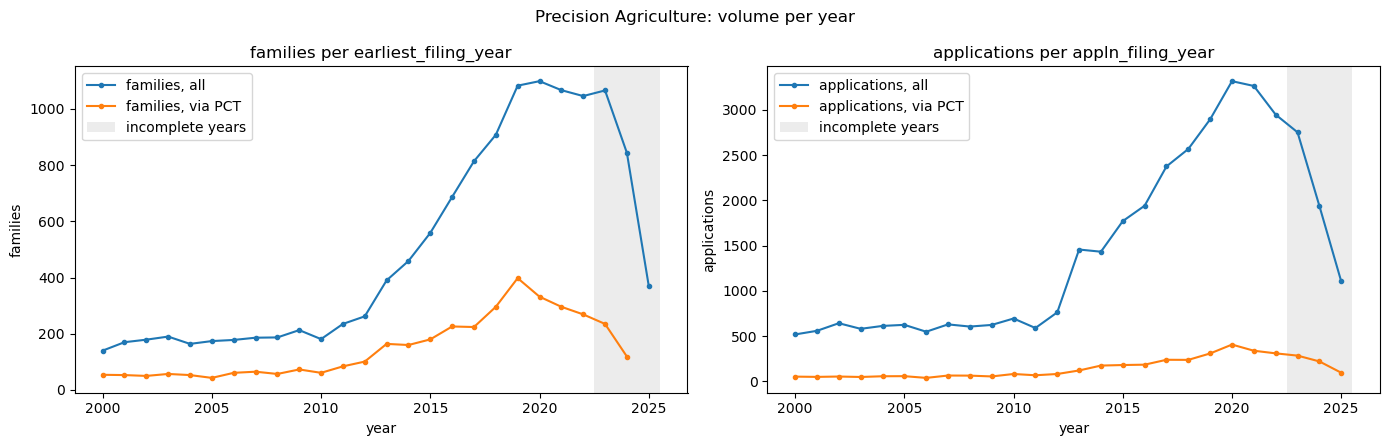

In [9]:
volume = pd.concat(
    [count_per_year(s).assign(series="all") for s in SCOPES]
    + [count_per_year(s, only_pct=True).assign(series="via PCT") for s in SCOPES],
    ignore_index=True,
)

fig, axes = side_by_side(f"{SECTOR_NAME}: volume per year", sharex=True)
for ax, scope in zip(axes, SECTOR_SCOPES):
    data = volume.query("scope == @scope.name and level == @scope.level")
    for series, grp in data.groupby("series"):
        ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=f"{UNIT_LABEL[scope.level]}, {series}")
    shade_truncated(ax)
    year_col = FAMILY_TIME_COLUMN if scope.level == "family" else APPLN_TIME_COLUMN
    ax.set(title=f"{UNIT_LABEL[scope.level]} per {year_col}", xlabel="year", ylabel=UNIT_LABEL[scope.level])
    ax.legend()
plt.tight_layout()
plt.show()

### 7.1 The same sector, three ways to date it

The choice of year shifts the curve. Here the sector's applications are dated with each of the three columns, together with the families dated by their earliest priority year.

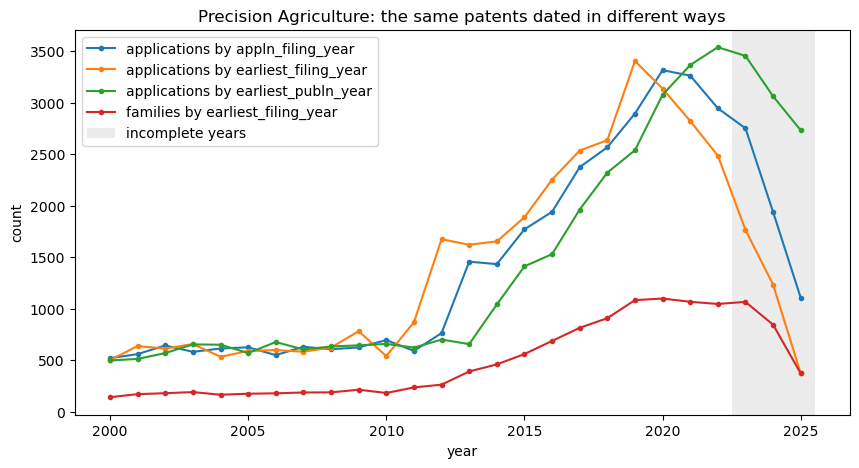

In [10]:
dating = pd.concat(
    [
        count_per_year(Scope(SECTOR_NAME, "application", application_scope(sector_ids, col)))
        .assign(series=f"applications by {col}")
        for col in ("appln_filing_year", "earliest_publn_year", "earliest_filing_year")
    ]
    + [volume.query("scope == @SECTOR_NAME and level == 'family' and series == 'all'")
       .assign(series=f"families by {FAMILY_TIME_COLUMN}")],
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(10, 5))
for series, grp in dating.groupby("series"):
    ax.plot(grp["year"], grp["n"], marker="o", ms=3, label=series)
shade_truncated(ax)
ax.set(title=f"{SECTOR_NAME}: the same patents dated in different ways", xlabel="year", ylabel="count")
ax.legend()
plt.show()

What to notice: dating by **publication** shifts the curve to the right (≈18 months later) and makes recent years look complete; dating by **priority** places inventions at their origin; the **family** curve is lower because each invention counts once.

### 7.2 Growth: is the sector growing faster than patenting as a whole?

Patenting in general grows over time, so a sector that grows is not necessarily special. We therefore compare two percentages:

- **sector growth (%)** = (sector count in the last complete year − sector count in the first year) / sector count in the first year × 100;
- **growth of all patents (%)**: the same formula on the total number of unique applications (`appln_id`) or of unique families (`docdb_family_id`) in PATSTAT in a certain time range

If the sector grows by +150% while all patents grow by +60%, the sector is **gaining weight** in technology. If it grows by +20% while all patents grow by +60%, it is growing, but **less than patenting overall**. Incomplete years are excluded.

Small sectors move a lot from one year to the next: also look at the curve, not only at the two end points.

In [17]:
start, end = YEAR_MIN, LAST_COMPLETE_YEAR
totals = volume.query("series == 'all'").pivot_table(index="year", columns=["level", "scope"], values="n")

growth = pd.DataFrame({
    f"count in {start}": totals.loc[start],
    f"count in {end}": totals.loc[end],
    f"growth {start}-{end} (%)": (totals.loc[end] / totals.loc[start] - 1) * 100,
}).loc[[(lvl, s) for lvl in LEVELS for s in ("all patents", SECTOR_NAME)]]

growth.style.format({f"count in {start}": "{:,.0f}", f"count in {end}": "{:,.0f}",
                     f"growth {start}-{end} (%)": "{:+.1f}%"})

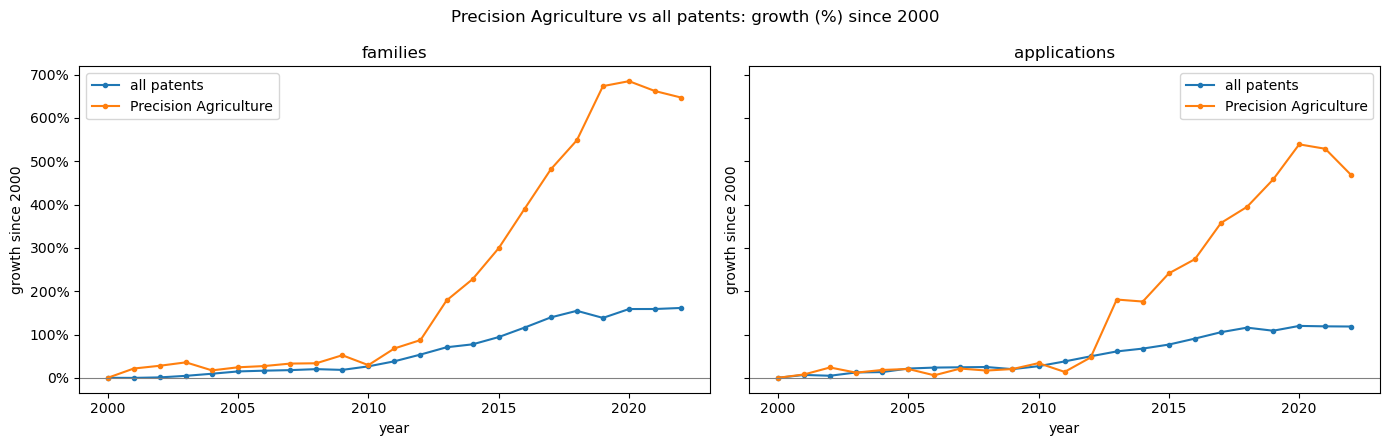

In [18]:
# Growth (%) of each year with respect to the first year: sector vs all patents
growth_path = (totals.loc[start:end] / totals.loc[start] - 1) * 100

fig, axes = side_by_side(f"{SECTOR_NAME} vs all patents: growth (%) since {start}", sharey=True)
for ax, level in zip(axes, LEVELS):
    for scope_name in ("all patents", SECTOR_NAME):
        ax.plot(growth_path.index, growth_path[(level, scope_name)], marker="o", ms=3, label=scope_name)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(title=UNIT_LABEL[level], xlabel="year", ylabel=f"growth since {start}")
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Technology mix

### 8.1 CPC subclasses

Which subclasses dominate the sector, and how is the mix shifting? Each family (or application) is split equally across its CPC subclasses, so the shares sum to 100%. Many subclasses are *co-classifications*: a wave energy family is often also classified in, for example, power generation or ships. They show which neighbouring technologies the sector draws on.

In [21]:
cpc_mix = pd.concat([fractional_by_cpc_subclass(s) for s in SECTOR_SCOPES], ignore_index=True)
cpc_pooled = pd.concat([pool_other(cpc_mix[cpc_mix["level"] == lvl], "subclass").assign(level=lvl)
                        for lvl in LEVELS], ignore_index=True)

cpc_counts = complete_years(cpc_pooled).pivot_table(index="subclass", columns="level", values="n_frac",
                                                    aggfunc="sum", fill_value=0)[list(LEVELS)]
cpc_shares = share_table(cpc_counts)
cpc_shares["definition (fill in from the CPC scheme)"] = ""   # deck table: add the official titles
cpc_shares.style.format("{:.1f}%", subset=list(LEVELS))

level,family,application,definition (fill in from the CPC scheme)
subclass,,,
A01B,21.6%,18.0%,
A01D,14.8%,12.4%,
A01C,6.9%,7.1%,
C12N,5.7%,7.1%,
G05D,5.0%,4.9%,
G06Q,2.3%,0.0%,
Y02A,2.3%,0.0%,
A01F,2.3%,0.0%,
C07K,0.0%,3.8%,


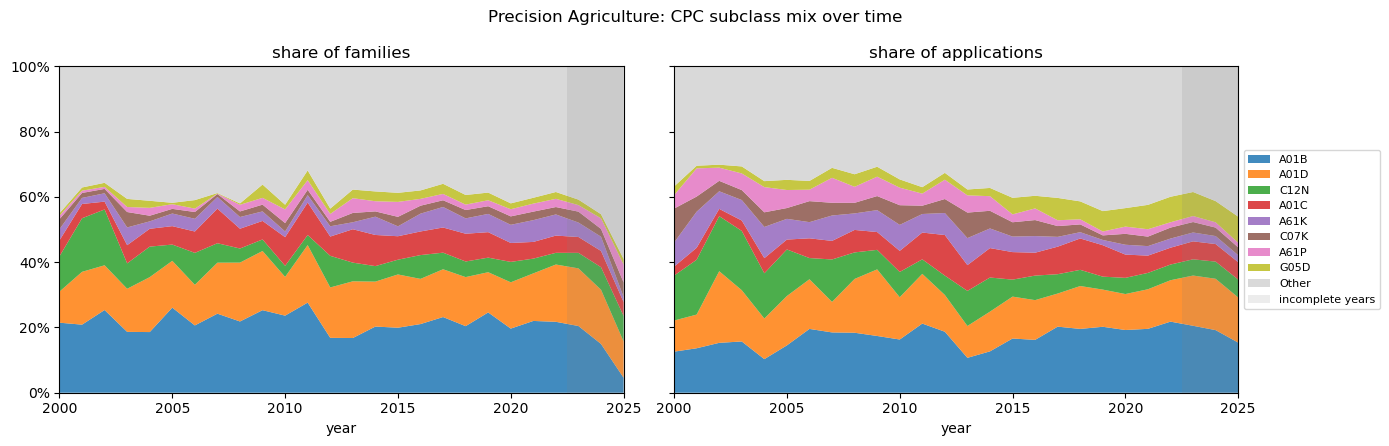

In [20]:
fig, axes = side_by_side(f"{SECTOR_NAME}: CPC subclass mix over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    stack_100(ax, share_over_time(cpc_pooled[cpc_pooled["level"] == level], "subclass"),
              f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

### 8.2 WIPO technology fields

WIPO groups all patents into **35 technology fields**, which belong to **5 technology sectors**: Electrical engineering, Instruments, Chemistry, Mechanical engineering, Other fields (tables `tls230` + `tls901`). It is a coarser view than CPC, the same for every country and every sector.

The question is simple: **of 100 sector families, how many are in each technology sector?** For example, *"15% of wave energy families are in Instruments and 80% in Mechanical engineering"*. The shares sum to 100%.

In [22]:
field_names = patstat.df(
    db.query(TLS901_TECHN_FIELD_IPC.techn_field_nr, TLS901_TECHN_FIELD_IPC.techn_field,
             TLS901_TECHN_FIELD_IPC.techn_sector).distinct()
).drop_duplicates("techn_field_nr")

fields = (
    pd.concat([fractional_by_techn_field(s) for s in SECTOR_SCOPES], ignore_index=True)
    .merge(field_names, on="techn_field_nr", how="left")
)

techn_sector_counts = complete_years(fields).pivot_table(index="techn_sector", columns="level", values="n_frac",
                                                         aggfunc="sum", fill_value=0)[list(LEVELS)]
techn_sector_shares = share_table(techn_sector_counts)
pct_format(techn_sector_shares)

level,family,application
techn_sector,,
Mechanical engineering,54.7%,49.8%
Chemistry,18.9%,25.5%
Instruments,14.1%,13.6%
Electrical engineering,11.5%,10.4%
Other fields,0.8%,0.6%
Total,100.0%,100.0%


In [ ]:
# One bar per level, split into the 5 technology sectors (each bar = 100%)
bars = techn_sector_shares.drop("Total").T

fig, ax = plt.subplots(figsize=(11, 3))
left = np.zeros(len(bars))
for techn_sector in bars.columns:
    values = bars[techn_sector].values
    ax.barh([UNIT_LABEL[l] for l in bars.index], values, left=left, label=techn_sector)
    for y, (x0, v) in enumerate(zip(left, values)):
        if v >= 5:
            ax.text(x0 + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += values
ax.set(title=f"{SECTOR_NAME}: split across the 5 WIPO technology sectors", xlim=(0, 100))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

The same split at the finer level of the 35 fields (largest fields, the rest in **Other**):

In [ ]:
field_counts = complete_years(fields).pivot_table(index="techn_field", columns="level", values="n_frac",
                                                  aggfunc="sum", fill_value=0)[list(LEVELS)]
top_fields = field_counts["family"].nlargest(TOP_N).index
field_counts = field_counts.groupby(field_counts.index.where(field_counts.index.isin(top_fields), "Other")).sum()
pct_format(share_table(field_counts))

## 9. Geography

### 9.1 Filing offices: the IP5

The **IP5** are the five largest patent offices in the world, which together receive most of the world's patent applications:

| Code (`appln_auth`) | Office |
|---|---|
| `EP` | European Patent Office (EPO) |
| `US` | United States Patent and Trademark Office (USPTO) |
| `CN` | China National Intellectual Property Administration (CNIPA) |
| `JP` | Japan Patent Office (JPO) |
| `KR` | Korean Intellectual Property Office (KIPO) |

Where do applicants seek protection? Offices with many sector filings are the markets that applicants consider worth protecting.

- **Application level**: each application is filed at exactly one office, so we can split the sector's applications across offices and the shares sum to 100% (IP5, `WO` for PCT applications, and Other offices).
- **Family level**: one family is usually filed at several offices, so the office counts of a family overlap and **do not** sum to the number of families. We therefore show counts, not shares: "how many inventions are protected at each office".

In [ ]:
offices = pd.concat([count_by_office(s) for s in SECTOR_SCOPES], ignore_index=True)
offices["office"] = offices["office"].where(offices["office"].isin(IP5_OFFICES + ("WO",)), "Other")
offices = offices.groupby(["level", "office", "year"], as_index=False)["n"].sum()

# Application level: shares across offices (sum to 100%)
office_counts = complete_years(offices.query("level == 'application'")).groupby("office")["n"].sum().to_frame("applications")
office_shares = share_table(office_counts)
print(f"Share of the sector's applications filed at the IP5: {office_shares.loc[list(IP5_OFFICES), 'applications'].sum():.1f}%")
pct_format(office_shares)

In [ ]:
fig, axes = side_by_side(f"{SECTOR_NAME}: filings at the IP5 offices", sharex=True)
for ax, level in zip(axes, LEVELS):
    data = offices.query("level == @level and office in @IP5_OFFICES")
    for office, g in data.groupby("office"):
        ax.plot(g["year"], g["n"], marker="o", ms=3, label=office)
    shade_truncated(ax)
    title = ("families with an application at the office" if level == "family"
             else "applications filed at the office")
    ax.set(title=title, xlabel="year", ylabel=UNIT_LABEL[level])
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### 9.2 Applicant and inventor countries (fractional counts)

- **Applicant country**: where the *owners* of the technology are (which firms and countries control it).
- **Inventor country**: where the *research* is carried out.

A gap between the two (e.g. inventors in one country, applicants in another) may point to foreign R&D centres or acquisitions. Each column sums to 100%.

In [ ]:
countries = pd.concat(
    [fractional_by_country(s, role) for s in SECTOR_SCOPES for role in ("applicant", "inventor")],
    ignore_index=True,
)

country_counts = complete_years(countries).pivot_table(index="ctry", columns=["level", "role"], values="n_frac",
                                                       aggfunc="sum", fill_value=0)
country_counts = country_counts[[(lvl, role) for lvl in LEVELS for role in ("applicant", "inventor")]]
top_countries = country_counts[("family", "applicant")].nlargest(TOP_N).index
country_counts = country_counts.groupby(country_counts.index.where(country_counts.index.isin(top_countries), "Other")).sum()
pct_format(share_table(country_counts))

##PS: watch out for missing values!

In [ ]:
fig, axes = side_by_side(f"{SECTOR_NAME}: applicant countries over time", sharey=True)
for ax, level in zip(axes, LEVELS):
    data = countries.query("role == 'applicant' and level == @level")
    stack_100(ax, share_over_time(pool_other(data, "ctry"), "ctry"), f"share of {UNIT_LABEL[level]}")
axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

---

← [01 · PATSTAT on TIP](01_patstat_basics.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md) &nbsp;|&nbsp; — →